# 02　PSK：解调

从 `mod_02_8PSK.npz` 读**原始字**，把接收链一步步重跑。本册不碰 PL / DMA，断电重启后也能跑。

```
寻活跃区 → 去直流 → RRC 匹配滤波 → 环回方向自判 → 粗定时 / 粗频偏
      → 逐帧精同步（逐样点 + 带限 FFT）→ 判决引导锁相环 → Gray 逆映射 → 比特
```

| 环节 | 8PSK 的做法 |
|---|---|
| 定时 | ZC 前导（与星座无关）+ 三次插值分数延迟 |
| 频偏 | 前导相位斜率拟合 + PLL 收尾 |
| 判决 | 最近相位（8 个相位点） |
| 相位 | 开二阶判决引导锁相环（`track=True`） |

**前导与星座无关**，这是五套接收链能共用一份同步代码的根本原因：换调制只换
`Const`（`map` / `demap` / `slice` / `margin` 四个方法），同步与 PLL 一行都不改。

## 1　导入与输入文件

In [1]:
import os
import sys

# 库目录：mod_dsp / mod_cases / 全部 .npz 都在这里（notebook 目录只放 .ipynb）
LIB  = "/home/xilinx/modulation"
QPSK = "/home/xilinx/qpsk"        # qpsk_dsp / qpsk_hw / qpsk_init / run_test
for _p in (LIB, QPSK):
    if os.path.isdir(_p) and _p not in sys.path:
        sys.path.insert(0, _p)

CASE = "8PSK"
N_TX, N_DEMOD, N_VERIFY = 1, 2, 3
# 抓包（第 N_TX 册写，第 N_DEMOD / N_VERIFY 册读）与指标（第 N_DEMOD 册写）
CAP_NPZ = os.path.join(LIB, "mod_%02d_%s.npz" % (N_TX, CASE))
DEM_NPZ = os.path.join(LIB, "mod_%02d_%s.npz" % (N_DEMOD, CASE))

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

%matplotlib inline

import mod_dsp as M
import mod_cases as C

# font.family 列表触发逐字形回退（mpl≥3.6）：拉丁取自 DejaVu，中文取本机
# 已有的 CJK 字体（板上 Droid Sans Fallback / Windows 雅黑）。只列**已安装**的
# 名字，否则 matplotlib 会为每个字形打一行 findfont 警告（实测上千行）。
import matplotlib.font_manager as _fm
_avail = {f.name for f in _fm.fontManager.ttflist}
_fam = [n for n in ("DejaVu Sans", "Microsoft YaHei", "Noto Sans CJK SC",
                    "WenQuanYi Zen Hei", "Droid Sans Fallback") if n in _avail]
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 9,
    "axes.titlesize": 10, "legend.fontsize": 8,
    "font.family": _fam or ["DejaVu Sans"],
    "axes.unicode_minus": False,
})

SPEC = next(s for s in (C.DIGITAL_CASES + C.ANALOG_CASES) if s["name"] == CASE)
KIND = "digital" if "scheme" in SPEC else "analog"

print("mod_dsp  :", M.__file__)
print("mod_cases:", C.__file__)
print("案例     : %s（%s）" % (CASE, "数字" if KIND == "digital" else "模拟"))
print("库目录   :", LIB)
print("抓包文件 :", CAP_NPZ)

mod_dsp  : /home/xilinx/modulation/mod_dsp.py
mod_cases: /home/xilinx/modulation/mod_cases.py
案例     : 8PSK（数字）
库目录   : /home/xilinx/modulation
抓包文件 : /home/xilinx/modulation/mod_01_8PSK.npz


In [2]:
if not os.path.exists(CAP_NPZ):
    raise FileNotFoundError(
        "缺 %s —— 先跑 %02d_%s_tx_rx.ipynb 第 4 节"
        % (CAP_NPZ, N_TX, "%s" % CASE))

z = np.load(CAP_NPZ, allow_pickle=False)
print("抓包 %s（%.2f MB）" % (os.path.basename(CAP_NPZ),
                             os.path.getsize(CAP_NPZ) / 1e6))
print("  字 %d，原始长度 %d，突发长 %d 点，字率 %.3f MHz"
      % (len(z["words"]), int(z["n_real"]), int(z["bb_len"]),
         float(z["fs_word"]) / 1e6))

抓包 mod_01_8PSK.npz（0.31 MB）
  字 128640，原始长度 4194299，突发长 43648 点，字率 256.000 MHz


## 2　解调

数字：逐帧精同步 + 判决

In [3]:
r = C.load_and_demod(CAP_NPZ, verbose=True)
m, dbg = r["metrics"], r["dbg"]

print()
print("  %-9s %7s %7s %9s %8s %8s %10s  %s"
      % ("图样", "比特", "错位", "BER", "EVM%", "余量", "t0", ""))
print("  " + "-" * 74)
for f in r["res"]:
    print("  %-9s %7d %7d %9.1e %8.2f %8.3f %10.1f%s"
          % (f["tag"], f["n"], f["err"], f["ber"], f["evm"], f["margin"],
             f["t0"], "" if f["ok"] else "   <- 失败"))
print("  " + "-" * 74)
t0s = np.array([f["t0"] for f in r["res"]], dtype=float)
d_t = np.diff(t0s)
print("  合计 %d 帧 / %d 比特，误 %d 位，EVM max %.2f%%，余量 min %.3f"
      % (len(r["res"]), m["tot"], m["err"], m["evm_max"], m["margin_min"]))
print("  残余频偏中位 %+.0f Hz，帧起点间距 %.2f ± %.2f 点"
      % (m["cfo"], np.mean(d_t), np.std(d_t)))

  活跃区 [19456,64512)  去直流 +0+0j  方向 共轭(已翻转)  峰滞后 1567  粗频偏 -0 Hz

  图样             比特      错位       BER     EVM%       余量         t0  
  --------------------------------------------------------------------------
  rand         1536       0   0.0e+00     2.39    0.900    21071.3
  zeros        1536       0   0.0e+00     0.98    0.922    25807.2
  ones         1536       0   0.0e+00     0.99    0.966    30543.3
  alt          1536       0   0.0e+00     2.52    0.918    35279.3
  aa           1536       0   0.0e+00     2.52    0.961    40015.2
  55           1536       0   0.0e+00     2.56    0.913    44751.3
  cnt          1536       0   0.0e+00     2.31    0.914    49487.2
  prbs9        1536       0   0.0e+00     2.42    0.904    54223.2
  onehot       1536       0   0.0e+00     1.02    0.955    58959.3
  --------------------------------------------------------------------------
  合计 9 帧 / 13824 比特，误 0 位，EVM max 2.56%，余量 min 0.900
  残余频偏中位 -30 Hz，帧起点间距 4736.00 ± 0.05 点


**应该看到**：9 帧全部 `错位 0`、BER `0.0e+00`，EVM max 在 1%~4%，余量 ≥ 0.9，
帧起点间距等于 `(载荷 + 前导 + 保护) × SPS`，抖动 < 0.1 点。

## 3　存盘

只存标量指标，供 `03_PSK_verify` 出判定表；原始数据仍在抓包 `.npz` 里，
要重算直接重跑本册。

In [4]:
out = {}
for k, v in r["metrics"].items():
    if isinstance(v, (int, float, np.integer, np.floating)):
        out[k] = np.float64(v)
out["case"] = np.array(CASE)

np.savez_compressed(DEM_NPZ, **out)
print("已保存 %s（%.1f KB，%d 个指标）"
      % (DEM_NPZ, os.path.getsize(DEM_NPZ) / 1e3, len(out)))
print("指标：", ", ".join(sorted(k for k in out if k != "case")))

已保存 /home/xilinx/modulation/mod_02_8PSK.npz（1.1 KB，6 个指标）
指标： cfo, err, evm_max, margin_min, tot


## 4　图

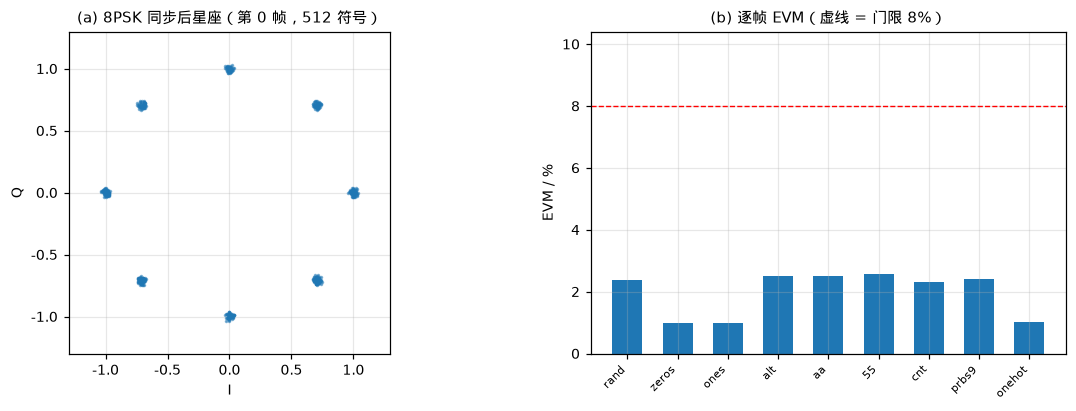

In [5]:
fig = plt.figure(figsize=(12.6, 3.8))
gs = fig.add_gridspec(1, 2, wspace=0.26)

sy = r["res"][0]["syms"]
ax = fig.add_subplot(gs[0, 0])
ax.plot(sy.real, sy.imag, ".", ms=2.6, alpha=0.5)
lim = 1.25 * max(1.0, float(np.max(np.abs(sy))))
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
ax.set_xlabel("I"); ax.set_ylabel("Q")
ax.set_title("(a) %s 同步后星座（第 0 帧，%d 符号）" % (CASE, len(sy)))

ax = fig.add_subplot(gs[0, 1])
x_ax = np.arange(len(r["res"]))
ax.bar(x_ax, [f["evm"] for f in r["res"]], width=0.6)
ax.axhline(C.LIM["evm_max"], color="r", ls="--", lw=0.9)
ax.set_xticks(x_ax)
ax.set_xticklabels([f["tag"] for f in r["res"]], rotation=45, ha="right",
                   fontsize=7)
ax.set_ylabel("EVM / %"); ax.set_ylim(0, 1.3 * C.LIM["evm_max"])
ax.set_title("(b) 逐帧 EVM（虚线 = 门限 %.0f%%）" % C.LIM["evm_max"])
plt.show()

## 5　判读要点

| 现象 | 含义 | 处置 |
|---|---|---|
| 某一帧全错，其余正常 | 帧定位错位一帧 | 看 `find_active` 起点与前导相关峰 |
| EVM 整体偏大 | 环回衰减过大 / ADC 饱和 | 查 SMA 与衰减器，回发送册重抓 |
| 相邻相位互换 | Gray 映射不一致 | `map` 与 `demap` 必须用同一套 `_gray_int` |